<!-- d2l:prose id=discrete-diffusion-md-1 fw=all -->

# Discrete Diffusion

Every model in the preceding sections relied on adding Gaussian noise to continuous vectors: points in $\mathbb{R}^2$, pixel intensities, or autoencoder latents. Discrete sequences such as text tokens, source code, or quantized image tokens cannot be perturbed by small additive real numbers. While autoregressive models (that section) generate $L$ tokens in $L$ sequential forward passes from left to right, discrete diffusion models generate multiple tokens in parallel per network evaluation with bidirectional context.

To define diffusion on a finite vocabulary, @Hoogeboom.Nielsen.Jaini.ea.2021 and @Austin.Johnson.Ho.ea.2021 replaced Gaussian perturbation with a discrete-state Markov chain governed by transition matrices $\mathbf{Q}_t$. On text and discrete codes, the most effective corruption process is the *absorbing (masking) kernel*, which independently replaces tokens with a mask symbol $[\textrm{M}]$ until the sequence is completely erased. Under this absorbing chain, the variational lower bound of that section simplifies to a weighted masked cross-entropy objective [@Sahoo.Arriola.Schiff.ea.2024; @Shi.Han.Wang.ea.2024]. In this section we derive the absorbing Markov chain and its variational bound, analyze the independence error incurred when unmasking multiple tokens in parallel on a quantized two-token version of the three-mode mixture and on binary Fashion-MNIST images, and connect masked diffusion to autoregressive and masked language models (that section and that section).

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
from scipy.special import ndtr, xlogy

In [3]:
torch.set_float32_matmul_precision('high')  # tf32 matmuls on tensor cores

<!-- d2l:prose id=discrete-diffusion-md-2 fw=all -->

## Corrupting Tokens

We ask of a forward process for tokens what the Gaussian chain of
that section provided: marginals and posteriors
in closed form, and an end state that carries no information about the
data.

### Transition Matrices

First a change of notation. To match the papers on discrete diffusion,
$t = 1, \ldots, T$ is now an integer that counts steps, the role $k$
played for the Gaussian chain. The network still receives $t/T$, the time
on the chapter's clock.

Let a token take one of $K$ values, written as a one-hot row vector
$\mathbf{x} \in \{0, 1\}^K$. Noise for a token is a random change of its
value, given by *transition matrices* $\mathbf{Q}_t \in [0, 1]^{K \times K}$
whose rows sum to one: $[\mathbf{Q}_t]_{ij}$ is the probability of moving
from value $i$ to value $j$ at step $t$. These are
the row-stochastic matrices of Markov chain Monte Carlo
(that section): a distribution is a row vector, multiplied
by $\mathbf{Q}_t$ from the right. Hence

$$
q(\mathbf{x}_t \mid \mathbf{x}_{t-1}) = \mathrm{Cat}(\mathbf{x}_t;\ \mathbf{x}_{t-1} \mathbf{Q}_t),
$$

where $\mathrm{Cat}(\mathbf{x}; \mathbf{p})$ is the categorical
distribution with probability vector $\mathbf{p}$, here the row of
$\mathbf{Q}_t$ selected by the current value. A sequence of $L$ tokens is
corrupted by running the chain at every position independently. Composing
two transitions multiplies their matrices, so by induction on $t$ the
marginal after $t$ steps is

$$
q(\mathbf{x}_t \mid \mathbf{x}_0) = \mathrm{Cat}(\mathbf{x}_t;\ \mathbf{x}_0 \bar{\mathbf{Q}}_t),
\qquad \bar{\mathbf{Q}}_t = \mathbf{Q}_1 \mathbf{Q}_2 \cdots \mathbf{Q}_t.
$$

The posterior of one step given both of its ends follows from Bayes' rule
and the Markov property,

$$
\begin{aligned}
q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)
&= \frac{q(\mathbf{x}_t \mid \mathbf{x}_{t-1})\, q(\mathbf{x}_{t-1} \mid \mathbf{x}_0)}{q(\mathbf{x}_t \mid \mathbf{x}_0)} \\
&= \mathrm{Cat}\!\left(\mathbf{x}_{t-1};\ \frac{\mathbf{x}_t \mathbf{Q}_t^\top \odot \mathbf{x}_0 \bar{\mathbf{Q}}_{t-1}}{\mathbf{x}_0 \bar{\mathbf{Q}}_t \mathbf{x}_t^\top}\right),
\end{aligned}
$$

where $\odot$ is the elementwise product: each possible predecessor is
weighted by its probability given the start and by its probability of
leading to the observed $\mathbf{x}_t$.

A binary token that flips with probability $0.1$ at every step shows the
posterior at work. Here
$\mathbf{Q}_1 = \mathbf{Q}_2 = \left(\begin{smallmatrix} 0.9 & 0.1 \\ 0.1 & 0.9 \end{smallmatrix}\right)$.
Start from the first value, $\mathbf{x}_0 = (1, 0)$, and suppose that
after two steps the token shows the second value, $\mathbf{x}_2 = (0, 1)$.
This happens with probability $0.9 \cdot 0.1 + 0.1 \cdot 0.9 = 0.18$, the
denominator. For the middle state,
$\mathbf{x}_2 \mathbf{Q}_2^\top = (0.1, 0.9)$ and
$\mathbf{x}_0 \bar{\mathbf{Q}}_1 = (0.9, 0.1)$. Their elementwise product
is $(0.09, 0.09)$, and dividing by $0.18$ gives $(1/2, 1/2)$. The token
flipped once, and given both ends the flip is equally likely to have
happened at the first step or at the second.

### The Absorbing Kernel

The bound needs a closed form for $\bar{\mathbf{Q}}_t$, and the sampler a
known starting state. The *absorbing kernel* of
@Austin.Johnson.Ho.ea.2021 provides both. It enlarges the vocabulary by
one value, the *mask* $[\textrm{M}]$, and moves each token there with
probability $\beta_t$ at step $t$; a masked token stays masked:

$$
\mathbf{Q}_t = (1 - \beta_t)\, \mathbf{I} + \beta_t\, \mathbf{1} \mathbf{e}_{\textrm{M}}^\top,
$$

with $\mathbf{1}$ the all-ones column vector and $\mathbf{e}_{\textrm{M}}$
the one-hot column vector of the mask, so that every row of
$\mathbf{1} \mathbf{e}_{\textrm{M}}^\top$ puts all its mass on the mask.

Products of such matrices collapse. Write
$\mathbf{P} = \mathbf{1} \mathbf{e}_{\textrm{M}}^\top$. Since
$\mathbf{e}_{\textrm{M}}^\top \mathbf{1} = 1$, we have
$\mathbf{P}^2 = \mathbf{P}$, and therefore
$(a\mathbf{I} + b\mathbf{P})(c\mathbf{I} + d\mathbf{P}) = ac\, \mathbf{I} + (ad + bc + bd)\, \mathbf{P}$.
When $a + b = c + d = 1$ the second coefficient equals $1 - ac$, so the
coefficient of $\mathbf{I}$ multiplies along the chain. Let
$\bar{\alpha}_t = \prod_{s \leq t} (1 - \beta_s)$, the same product as for
the Gaussian chain of that section. There it was
the squared weight of the clean point; here it has a more direct meaning,
the probability that a token survives $t$ steps without being masked. Then

$$
\bar{\mathbf{Q}}_t = \bar{\alpha}_t\, \mathbf{I} + (1 - \bar{\alpha}_t)\, \mathbf{1}\mathbf{e}_{\textrm{M}}^\top.
$$

The chain never confuses one token with another; it only erases. A
schedule with $\bar{\alpha}_T = 0$ ends at the fully masked sequence
(the figure), which carries no information about the
data, as the Gaussian chain ends at pure noise. The other common choice, the
*uniform kernel*, resamples a token uniformly from the vocabulary
[@Hoogeboom.Nielsen.Jaini.ea.2021] (Exercise
1).

![The absorbing chain on nine tokens. Forward, each token is independently replaced by the mask (drawn as ?) with probability $\beta_t$ per step and stays masked; after $T$ steps every token is masked. Reverse, the model predicts masked tokens from the partially masked sequence, and a revealed token is never changed.](../img/mdl-diffusion-masking.svg)

We use the absorbing kernel from now on. It gave the best likelihoods on
text in the comparisons of Austin et al., and its posterior is as simple
as a posterior can be. It also gives something up. In reverse the chain
only reveals, so the sampler commits to every token it writes, just as a
left-to-right model does. Chains that resample tokens, such as the uniform
kernel, and samplers that mask revealed tokens again, such as ReMDM
[@Wang.Schiff.Sahoo.ea.2025], can revise an early mistake
(that section).

## The Masked Bound

To train a reverse chain we need a loss, and the variational bound of
that section offers one.

### The Same Bound, a Different Target

The reverse model is a Markov chain
$p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$, started from
the all-mask sequence. that section bounded the
negative log-likelihood of such a chain by

$$
\begin{aligned}
-\log p_{\boldsymbol{\theta}}(\mathbf{x}_0) \leq L_{\textrm{VLB}}
&= D_{\textrm{KL}}\big(q(\mathbf{x}_T \mid \mathbf{x}_0)\, \|\, p(\mathbf{x}_T)\big) \\
&\quad + \sum_{t=2}^{T} \mathbb{E}_q\Big[D_{\textrm{KL}}\big(q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)\, \|\, p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1} \mid \mathbf{x}_t)\big)\Big] \\
&\quad + \mathbb{E}_q\big[-\log p_{\boldsymbol{\theta}}(\mathbf{x}_0 \mid \mathbf{x}_1)\big].
\end{aligned}
$$

This is the negative of the evidence lower bound of
that section, with the forward chain as the
variational distribution. Its derivation used only the Markov property and Bayes' rule, so it holds for tokens as it stands.

What changes is the target. For Gaussian noise the network predicted the
noise, the velocity or the clean point, each an affine function of one
posterior mean $\mathbb{E}[\mathbf{x}_0 \mid \mathbf{x}_t]$
(that section). For a one-hot token that posterior
mean is the vector of probabilities of the values the clean token might
have, so predicting that distribution is the discrete form of the
denoiser the chapter started from. Following
@Austin.Johnson.Ho.ea.2021, the network outputs, for each position
$i$, a distribution
$p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_t)$ over the clean
values given the whole corrupted sequence, and the reverse transition
averages the true posterior over this prediction,

$$
p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1} \mid \mathbf{x}_t)
= \sum_{\hat{\mathbf{x}}_0} q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \hat{\mathbf{x}}_0)\, p_{\boldsymbol{\theta}}(\hat{\mathbf{x}}_0 \mid \mathbf{x}_t),
$$

position by position, with the prediction at an unmasked position taken
to be the observed token. For a single token, a perfect prediction makes
this the true reverse transition (Exercise
3a). For a sequence it falls short
in one respect: positions that revert in the same step are drawn
independently of one another, whereas the true reverse transition draws
them jointly. Much of this section is about what that shortfall costs.

### The Posterior of the Absorbing Chain

**Proposition (posterior of the absorbing chain).** *Under the absorbing
kernel with $\beta_1 > 0$, so that $\bar{\alpha}_t < 1$ for every
$t \geq 1$, consider one position with clean value $\mathbf{x}_0 \neq [\textrm{M}]$.
If $\mathbf{x}_t = \mathbf{x}_0$, then $\mathbf{x}_{t-1} = \mathbf{x}_0$
with probability one. If $\mathbf{x}_t = [\textrm{M}]$, then*

$$
\begin{aligned}
q(\mathbf{x}_{t-1} = \mathbf{x}_0 \mid \mathbf{x}_t = [\textrm{M}], \mathbf{x}_0) &= \frac{\bar{\alpha}_{t-1} - \bar{\alpha}_t}{1 - \bar{\alpha}_t}, \\
q(\mathbf{x}_{t-1} = [\textrm{M}] \mid \mathbf{x}_t = [\textrm{M}], \mathbf{x}_0) &= \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t},
\end{aligned}
$$

*and no other value has positive probability.*

**Proof.** Evaluate the equation with
the equation and
the equation. The vector
$\mathbf{x}_0 \bar{\mathbf{Q}}_{t-1}$ puts mass $\bar{\alpha}_{t-1}$ on
$\mathbf{x}_0$ and $1 - \bar{\alpha}_{t-1}$ on the mask, so only these two
predecessors are possible. If $\mathbf{x}_t = \mathbf{x}_0$, the vector
$\mathbf{x}_t \mathbf{Q}_t^\top$ has the entry $1 - \beta_t$ at
$\mathbf{x}_0$ and the entry $0$ at the mask, because a mask never returns
to a token, and the posterior is a point mass. If
$\mathbf{x}_t = [\textrm{M}]$, the entries are $\beta_t$ at
$\mathbf{x}_0$ and $1$ at the mask, so the unnormalized posterior is
$\bar{\alpha}_{t-1}\beta_t$ on $\mathbf{x}_0$ and $1 - \bar{\alpha}_{t-1}$
on the mask. Their sum, $1 - \bar{\alpha}_{t-1}(1 - \beta_t) = 1 - \bar{\alpha}_t$,
is the denominator $q(\mathbf{x}_t = [\textrm{M}] \mid \mathbf{x}_0)$, and
$\bar{\alpha}_{t-1}\beta_t = \bar{\alpha}_{t-1} - \bar{\alpha}_t$.
$\blacksquare$

One step back, a masked token either stays masked or reverts to its clean
value. The reverse model the equation
therefore copies the unmasked positions of $\mathbf{x}_t$ and replaces each
masked one, independently, by a draw from
$p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_t)$ with the
probability of reverting.

### A Weighted Cross-Entropy

The reverse model copies what is visible and fills only masks, so only the
masked positions can cost anything in the bound. The next result, found in
this form by @Sahoo.Arriola.Schiff.ea.2024 and
@Shi.Han.Wang.ea.2024, is the central one of the section: what
they cost is a cross-entropy.

**Proposition (masked diffusion bound).** *For the absorbing kernel with
$\bar{\alpha}_0 = 1$, $\bar{\alpha}_t < 1$ for $t \geq 1$, and
$\bar{\alpha}_T = 0$, and the reverse model just described,*

$$
\begin{aligned}
L_{\textrm{VLB}}
&= \sum_{t=1}^{T} \frac{\bar{\alpha}_{t-1} - \bar{\alpha}_t}{1 - \bar{\alpha}_t}\;
\mathbb{E}_{q(\mathbf{x}_t \mid \mathbf{x}_0)}\Big[ \sum_{i \,:\, \mathbf{x}_t^i = [\textrm{M}]} -\log p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_t) \Big].
\end{aligned}
$$

**Proof.** The prior term vanishes: $\bar{\alpha}_T = 0$ makes
$q(\mathbf{x}_T \mid \mathbf{x}_0)$ the point mass on the all-mask
sequence, which is also $p(\mathbf{x}_T)$. Both
$q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)$ and
$p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$ factorize
over positions, so each divergence is a sum of per-position divergences.
At an unmasked position both distributions are the same point mass and
the divergence is zero. At a masked position write
$w_t = (\bar{\alpha}_{t-1} - \bar{\alpha}_t) / (1 - \bar{\alpha}_t)$. The
true posterior puts $1 - w_t$ on the mask and $w_t$ on $\mathbf{x}_0^i$;
the model puts $1 - w_t$ on the mask and
$w_t\, p_{\boldsymbol{\theta}}(\cdot \mid \mathbf{x}_t)$ on the tokens;
hence

$$
\begin{aligned}
D_{\textrm{KL}}
&= (1 - w_t) \log \frac{1 - w_t}{1 - w_t}
+ w_t \log \frac{w_t}{w_t\, p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_t)} \\
&= -w_t \log p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_t).
\end{aligned}
$$

This accounts for $t = 2, \ldots, T$. The reconstruction term is
$\mathbb{E}[-\log p_{\boldsymbol{\theta}}(\mathbf{x}_0 \mid \mathbf{x}_1)]$.
Since $w_1 = (1 - \bar{\alpha}_1)/(1 - \bar{\alpha}_1) = 1$, the model
replaces every position masked at step $1$ by a draw from
$p_{\boldsymbol{\theta}}(\cdot \mid \mathbf{x}_1)$ and copies the rest, so
this term equals the sum of
$-\log p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_1)$ over the
masked positions, which is the $t = 1$ term of the sum. $\blacksquare$

This is the loss of a masked language model with two changes: the
masking rate ranges over all levels from nothing to everything instead of
staying at one value, and each level carries its own weight. Divided by
$\log 2$ and the number of tokens, the bound is a code length in bits per
token (that section), the unit in which we will
read it on images.

Under the *linear schedule* $\bar{\alpha}_t = 1 - t/T$, a fraction $t/T$
of the tokens is masked at step $t$, and $w_t = (1/T)/(t/T) = 1/t$. An
error on a heavily masked sequence counts less than the same error on a
lightly masked one. Since the number of masked positions grows in
proportion to $t$, every step carries the same expected weighted count of
masked positions, $L/T$ for $L$ tokens; the steps differ only in how hard
their masked tokens are to predict.

The sum is also a Riemann sum. Write
$\ell(\mathbf{x}_0, \mathbf{x})$ for the cross-entropy on the masked
positions of $\mathbf{x}$, the inner sum of
the equation, and let $T \to \infty$ with
$\bar{\alpha}_t = \bar{\alpha}(t/T)$ for a decreasing function on the
chapter's clock, data at time $0$ and the all-mask sequence at time $1$.
Since $t$ now counts steps, we write $\tau = t/T$ for the time. Then
$w_t \approx -\bar{\alpha}'(\tau)/(T(1 - \bar{\alpha}(\tau)))$. Its factor
$1/T$ is the width $d\tau$ of one step, so the bound tends to

$$
\int_0^1 \frac{-\bar{\alpha}'(\tau)}{1 - \bar{\alpha}(\tau)}\, \mathbb{E}\big[\ell(\mathbf{x}_0, \mathbf{x}_\tau)\big]\, d\tau .
$$

Now substitute the masking probability $u = 1 - \bar{\alpha}(\tau)$ (in
this section $u$ is a probability, not a velocity). Since
$du = -\bar{\alpha}'(\tau)\, d\tau$, the integral becomes

$$
\int_0^1 \frac{1}{u}\, \mathbb{E}_u\big[\ell(\mathbf{x}_0, \mathbf{x})\big]\, du,
$$

where $\mathbb{E}_u$ masks each token independently with probability $u$.
For a network told the masking probability rather than the time, the
limit does not depend on the schedule, the discrete counterpart of the
schedule invariance of the Gaussian bound
(that section)
[@Kingma.Salimans.Poole.ea.2021].

In fact the best network needs neither. Which positions are masked is
decided by coin flips that never look at the tokens. Once the input shows
which positions are masked and what the others hold, the time adds nothing
about the hidden tokens. The best prediction at a masked position, the
conditional of its token given the visible ones, therefore does not depend
on the time at all [@Ou.Nie.Xue.ea.2025] (Exercise
4).

Readers of recent papers will meet this limit in another form: a
*continuous-time Markov chain* that masks each surviving token at the rate
$-\bar{\alpha}'(\tau)/\bar{\alpha}(\tau)$
[@Campbell.Benton.DeBortoli.ea.2022], reversed with the help of ratios
of probabilities between sequences that differ in one token
[@Lou.Meng.Ermon.2024]. For the absorbing kernel such a ratio is a
known function of time times the clean conditional our network predicts
[@Ou.Nie.Xue.ea.2025], so both views train the same object.

The function `masked_loss` estimates the bound with one step $t$ per
sequence, given the schedule `alpha_bar` (the values
$\bar{\alpha}_0, \ldots, \bar{\alpha}_T$) and the index `mask_id` of the mask; the
factor $T$ makes a uniformly drawn step unbiased for the sum over steps.
The sum runs over every axis after the first, so pairs of tokens and
images share the function. Our networks still receive $t/T$, to keep the
chapter's interfaces; Exercise 4
measures how little the trained pair model uses it.

In [4]:
def masked_loss(model, x0, t, alpha_bar, mask_id):
    """One-draw estimate of the masked bound per sequence, in nats."""
    T = len(alpha_bar) - 1
    shape = (-1,) + (1,) * (x0.dim() - 1)      # broadcast over positions
    masked = (torch.rand(x0.shape, device=x0.device)
              < (1 - alpha_bar[t]).view(shape))  # with prob. 1 - abar_t
    logits = model(torch.where(masked, mask_id, x0), t / T)
    nll = -torch.log_softmax(logits, -1).gather(-1, x0[..., None])[..., 0]
    w = (alpha_bar[t - 1] - alpha_bar[t]) / (1 - alpha_bar[t])  # 1/t if linear
    return (T * w.view(shape) * nll * masked).flatten(1).sum(1)

<!-- d2l:prose id=discrete-diffusion-md-3 fw=all -->

## Sampling by Unmasking

A trained network gives a distribution at every masked position.
Generation must decide which positions to fill, and when.

### Parallel Reveals and the Independence Error

Generation starts from the all-mask sequence. At step $t$, one forward
pass yields $p_{\boldsymbol{\theta}}(\cdot \mid \mathbf{x}_t)$ at every
masked position; each masked position draws a candidate token and accepts
it with probability $w_t$. As with the Gaussian samplers of
that section, we would rather not spend $T$ network
evaluations, so we choose levels $T = t_0 > t_1 > \cdots > t_S = 0$ and
jump between them. Skipping levels composes kernels, and by the collapse
shown above a product of absorbing kernels is again absorbing. The coarser
chain therefore has the marginals the equation at
its levels, and the proposition applies to it unchanged: the function
`unmask` jumps from $t_k$ to $t_{k+1}$ by revealing each masked token
with probability
$(\bar{\alpha}_{t_{k+1}} - \bar{\alpha}_{t_k}) / (1 - \bar{\alpha}_{t_k})$.

The reveal decisions never look at the network, so we can say in advance
when each token appears. The probabilities of staying masked,
$(1 - \bar{\alpha}_{t_{k+1}})/(1 - \bar{\alpha}_{t_k})$, multiply along
the jumps and telescope: a token is still masked at level $t_k$ with
probability $1 - \bar{\alpha}_{t_k}$, as under the forward chain. It is
therefore revealed in jump $k$, for $k = 0, \ldots, S - 1$, with
probability
$\Delta_k = \bar{\alpha}_{t_{k+1}} - \bar{\alpha}_{t_k}$, independently of
the other positions.

In [5]:
@torch.inference_mode()
def unmask(model, shape, steps, alpha_bar, mask_id):
    """Reveal tokens from the all-mask state in `steps` jumps."""
    T = len(alpha_bar) - 1
    levels = torch.linspace(T, 0, steps + 1).round().long().tolist()
    z = torch.full(shape, mask_id, device=alpha_bar.device)
    for t, s in zip(levels[:-1], levels[1:]):
        logits = model(z, torch.full(shape[:1], t / T, device=z.device))
        draw = torch.distributions.Categorical(logits=logits).sample()
        p = (alpha_bar[s] - alpha_bar[t]) / (1 - alpha_bar[t])  # reveal prob.
        reveal = (z == mask_id) & (torch.rand(shape, device=z.device) < p)
        z = torch.where(reveal, draw, z)
    return z

<!-- d2l:prose id=discrete-diffusion-md-4 fw=all -->

The network's prediction is a product over positions. Tokens revealed in
the same jump are therefore drawn independently of one another, each from
its own predicted distribution, while tokens revealed in different jumps
are drawn one after another, each conditioned on those already revealed.
What does this independence cost? Let us start with the smallest case in
which it can cost anything: two tokens.

The chapter's running example supplies them. It is the mixture of three
Gaussians in the plane with means $(-2.5, -1.5)$, $(2.5, -1.5)$ and
$(0, 2.5)$, weights $0.5$, $0.3$ and $0.2$, and standard deviation $0.5$
(that section). Quantizing the plane onto a
$32 \times 32$ grid over $[-5, 5]^2$ turns each sample into a pair of
tokens, the indices of its cell along the two axes. The table $p$ of the
pairs has three blobs, one per mode. Its marginals $p^1$ and $p^2$ have
three bumps along the first axis but only two along the second, since two
modes share a height. The product of the marginals, $p^1 \otimes p^2$,
draws the two tokens independently and puts a blob at every crossing of a
bump of one with a bump of the other: six blobs, three of them where no
data lie.

Now take an *exact* network, whose prediction at each masked position is
the true conditional of that token given the unmasked ones. With $S$
equal jumps under the linear schedule, $\Delta_k = 1/S$ for every jump,
so both tokens are revealed in the same jump with probability
$S \cdot (1/S)^2 = 1/S$, and in that event the pair comes from
$p^1 \otimes p^2$. Otherwise one token is drawn from its marginal and the
other later from its conditional, and the pair comes from $p$. The
sampler draws from the mixture

$$
\left(1 - \tfrac{1}{S}\right) p + \tfrac{1}{S}\, p^1 \otimes p^2 .
$$

In total variation, half the summed absolute difference of two
probability tables, this mixture lies $\mathrm{TV}(p^1 \otimes p^2, p)/S$
from $p$. The error falls as one over the number of steps and grows with
the dependence between the tokens.

We can predict the one-step error before computing anything. The three
phantom blobs of the product receive
$0.5 \cdot 0.2 + 0.3 \cdot 0.2 + 0.2 \cdot 0.8 = 0.32$ of the mass, and if
no blobs overlapped this would be the total variation. Cell probabilities
factorize into one-dimensional Gaussian integrals, so the cell below
computes $p$ exactly, with its entropy, the mutual information of the two
tokens, and the error of an exact network's sampler for four step counts.

In [6]:
mix = d2l.GaussianMixture.three_modes()
means, weights = np.float64(mix.means), np.float64(mix.weights)
K, T = 32, 32                 # vocabulary of each token; number of steps
edges = np.linspace(-5, 5, K + 1)
cdf = ndtr((edges - means[:, :, None]) / mix.std)  # (modes, axes, K + 1)
cdf[:, :, 0], cdf[:, :, -1] = 0, 1      # edge cells extend to infinity
cell = np.diff(cdf, axis=2)             # mass of each cell, per mode, axis
table = np.einsum('m,mi,mj->ij', weights, cell[:, 0], cell[:, 1])
p1, p2 = table.sum(1), table.sum(0)     # marginals of the two tokens
product = np.outer(p1, p2)
H = lambda p: -xlogy(p, p).sum()        # entropy in nats
tv = lambda p, q: np.abs(p - q).sum() / 2
mutual = H(p1) + H(p2) - H(table)
print(f'entropy {H(table):.3f} nats, mutual information {mutual:.3f} nats')
for S in (1, 2, 8, 32):
    print(f'{S:>2} steps, exact network: TV {tv(product, table) / S:.3f}')

entropy 4.840 nats, mutual information 0.479 nats
 1 steps, exact network: TV 0.314
 2 steps, exact network: TV 0.157
 8 steps, exact network: TV 0.039
32 steps, exact network: TV 0.010


<!-- d2l:prose id=discrete-diffusion-md-5 fw=all -->

The one-step sampler misplaces $0.314$ of the mass, a little less than
the predicted $0.32$ because neighboring blobs overlap slightly, and
thirty-two steps bring the error down to $0.010$.

### Confidence-Ordered Reveals

Many practical samplers do not reveal at random. MaskGIT
[@Chang.Zhang.Jiang.ea.2022] and the diffusion language model LLaDA
[@Nie.Zhu.You.ea.2025] draw a candidate at every masked position,
keep the candidates that are most probable under their own predicted
distributions, and mask the others again. This *confidence remasking*
chooses which tokens to reveal from the values it has drawn. Is that
better than a random order? The two-token table answers without any
training. For two tokens, confidence remasking draws both from their
marginals, $A \sim p^1$ and $B \sim p^2$, keeps the draw that is more
probable under its own marginal, and redraws the other from its
conditional given the kept one. Its output table is

$$
\begin{aligned}
q(a, b) &= p^1(a)\, P\big(p^2(B) \leq p^1(a)\big)\, p(b \mid a) \\
&\quad + p^2(b)\, P\big(p^1(A) < p^2(b)\big)\, p(a \mid b),
\end{aligned}
$$

where the first term keeps the draw $a$ of the first token and the second
keeps the draw $b$ of the second. The cell compares this table with those
of one step, two random jumps, and a fixed order (first token from its
marginal, second from its conditional).

In [7]:
c2 = table / p1[:, None]                # p(x2 | x1); each row sums to one
c1 = table / p2[None, :]                # p(x1 | x2); each column sums to one
keep1 = p1[:, None] >= p2[None, :]      # the draw of x1 is the likelier one
confidence = ((product * keep1).sum(1)[:, None] * c2
              + (product * ~keep1).sum(0)[None, :] * c1)
centers = (edges[:-1] + edges[1:]) / 2
grid = np.stack(np.meshgrid(centers, centers, indexing='ij'), -1)
mode = ((grid[:, :, None] - means) ** 2).sum(-1).argmin(-1)  # nearest mode
orders = {'one step': product, 'two random jumps': (product + table) / 2,
          'fixed order': p1[:, None] * c2, 'confidence': confidence}
print(f'{"order":>16} {"TV":>6} {"entropy":>8}  mass near the modes')
for name, q in orders.items():
    masses = ' '.join(f'{q[mode == k].sum():.3f}' for k in range(3))
    print(f'{name:>16} {tv(q, table):6.3f} {H(q):8.3f}  {masses}')

           order     TV  entropy  mass near the modes
        one step  0.314    5.319  0.482 0.321 0.197
two random jumps  0.157    5.216  0.491 0.310 0.199
     fixed order  0.000    4.840  0.500 0.300 0.200
      confidence  0.179    4.406  0.606 0.322 0.072


<!-- d2l:prose id=discrete-diffusion-md-6 fw=all -->

With exact conditionals, an order fixed before the tokens are drawn, left
to right or random, is exact when it reveals one token per step, as the
fixed order shows. Two random jumps reveal both tokens together half of
the time and halve the one-step error. Surprisingly, confidence
remasking, which also reveals one token per step but chooses its order
from the values it draws, lands farther from $p$ than two random jumps,
at $0.179$ against $0.157$. The formula shows why. A draw from a small
mode has a small marginal probability, so it tends to lose the comparison
and is the one redrawn, from a conditional given the winner that rarely
leads back to the small mode. The sampler seeks modes: the smallest mode
falls from $0.2$ to about $0.07$, and the entropy drops from $4.84$ to
$4.41$ nats. On text, lower entropy often reads as fluency, and with an
imperfect network it can help to reveal the easy positions first. But the
bound does not describe this sampler and cannot detect its bias. It
scores predictions under random masks, which is to say it describes the
random-order sampler.

## Trained Denoisers

So far every number came from an exact table. We now train networks,
first on the pair, where every error can be attributed, then on images.

### The Quantized Mixture

The network for the pair takes the one-hot encoding of both tokens, with
the mask as a thirty-third value at index $K$, together with the time
$t/T$, and outputs logits over the $32$ clean values at each position. The
schedule is linear with $T = 32$ steps.

In [8]:
class MaskedMLP(nn.Module):
    """Logits of both clean tokens of a pair, given the masked pair and t."""
    def __init__(self, K, hidden=256):
        super().__init__()
        self.K = K
        self.net = d2l.make_mlp([2 * (K + 1) + 1, hidden, hidden, 2 * K],
                                nn.SiLU())

    def forward(self, z, t):  # z: (n, 2) in {0, ..., K}, where K is the mask
        h = F.one_hot(z, self.K + 1).float().flatten(1)
        return self.net(torch.cat([h, t[:, None]], 1)).view(-1, 2, self.K)

def quantize(x):  # points in the plane to pairs of tokens in {0, ..., K - 1}
    return ((x + 5) / 10 * K).floor().long().clamp(0, K - 1)

alpha_bar = 1 - torch.arange(T + 1) / T     # the linear schedule

<!-- d2l:prose id=discrete-diffusion-md-7 fw=all -->

We train it with `d2l.train_regression`
(that section) on fresh draws from the mixture,
512 pairs per batch, each with a uniformly drawn step, with a learning rate
that decays along a cosine over 6,000 updates.

In [9]:
torch.manual_seed(0)
batch_fn = lambda: (quantize(mix.sample(512)), torch.randint(1, T + 1, (512,)))
loss_fn = lambda model, batch: masked_loss(model, *batch, alpha_bar,
                                           mask_id=K).mean()
_, pair_model, _ = d2l.train_regression(MaskedMLP(K), loss_fn, batch_fn,
                                        6000, cosine=True)

<!-- d2l:prose id=discrete-diffusion-md-8 fw=all -->

With two positions, the expectation in the bound can be computed exactly.
At each step there are three mask patterns with at least one mask. A
pattern with $m$ masks has probability $u^m (1 - u)^{2 - m}$, where
$u = 1 - \bar{\alpha}_t$, and the 1,024 pairs are weighted by the table.
This average cannot fall below the entropy of the table, the smallest
average negative log-likelihood any model attains
(that section). How close can a network come?

Let us work it out for an exact network, writing $X^1$ and $X^2$ for the
two tokens of a pair drawn from the table. The bound scores each token at
the step in which the reverse chain reveals it: the weight $w_t$ times the
probability $1 - \bar{\alpha}_t$ that the token is masked at step $t$ is
$\bar{\alpha}_{t-1} - \bar{\alpha}_t$, the probability that the reverse
chain reveals it at step $t$. When the tokens are revealed in different
steps, the first is predicted from its marginal and
the second from its conditional given the first; together they cost
$H(X^1) + H(X^2 \mid X^1) = H(X^1, X^2)$, nothing more. Two tokens
revealed in the same step are predicted independently from their
marginals and cost
$H(X^1) + H(X^2)$ instead of $H(X^1, X^2)$, an excess of the mutual
information $I(X^1; X^2)$ (that section). Under
the linear schedule each token is revealed at a given step with
probability $1/T$, so both are revealed in the same step with probability
$T \cdot (1/T)^2 = 1/T$, and an exact network attains

$$
H(X^1, X^2) + \frac{I(X^1; X^2)}{T}
$$

(Exercise 5 turns this
argument into a proof for every schedule). No network that predicts the
positions independently can go below this floor,
$4.840 + 0.479/32 \approx 4.855$ nats. As $T \to \infty$ no two tokens
are revealed in the same step, and the floor falls to the entropy.

In [10]:
@torch.inference_mode()
def exact_bound(model, table, alpha_bar, mask_id):
    """The bound averaged over the table, summed exactly over t and masks."""
    T, K = len(alpha_bar) - 1, len(table)
    pairs = torch.cartesian_prod(torch.arange(K), torch.arange(K))
    p, total = torch.tensor(table.flatten(), dtype=torch.float32), 0.0
    for t in range(1, T + 1):
        u = 1 - alpha_bar[t]
        w = (alpha_bar[t - 1] - alpha_bar[t]) / u
        for masked in torch.tensor([[1, 0], [0, 1], [1, 1]], dtype=torch.bool):
            z, m = torch.where(masked, mask_id, pairs), masked.sum()
            logp = torch.log_softmax(model(z, torch.full((K * K,), t / T)), -1)
            nll = -(logp.gather(-1, pairs[..., None])[..., 0] * masked).sum(1)
            total += u ** m * (1 - u) ** (2 - m) * w * (p @ nll)
    return float(total)

bound = exact_bound(pair_model, table, alpha_bar, mask_id=K)
print(f'exact bound {bound:.3f} nats; '
      f'entropy {H(table):.3f}, floor {H(table) + mutual / T:.3f}')

exact bound 4.856 nats; entropy 4.840, floor 4.855


<!-- d2l:prose id=discrete-diffusion-md-9 fw=all -->

The bound lies less than two hundredths of a nat above the entropy: the
model has learned the marginal of each token and its conditional given the
other. Almost all of the gap is the floor; the network's own excess over
the floor is of the order of a thousandth of a nat. The floor is not just
looseness of the bound: the thirty-two-step sampler of an exact network
models $(1 - 1/32)\, p + (1/32)\, p^1 \otimes p^2$ rather than $p$. The
bound and the sampler agree about what is lost.

Does the trained sampler lose the same? With two tokens its output table
can be summed instead of sampled. Each token is revealed in jump $k$ with
probability $\Delta_k$ (`pi` in the code), independently of the other.
Tokens revealed together are drawn from the network's two marginals at
that level, and a token revealed later from its
conditional given the first. `conditionals` reads these predictions from a
pair model, and `sampler_table` sums over the jumps; fed the true
marginals and conditionals, it must reproduce the exact network's errors
printed earlier.

In [11]:
@torch.inference_mode()
def conditionals(model, tau):
    """A pair model's predictions at time tau: both marginals with both
    tokens masked, then c2[a, b] = q(x2 = b | x1 = a), c1[a, b] = q(x1 = a |
    x2 = b)."""
    K = model.K                                   # also the mask index
    a, m = torch.arange(K), torch.full((K,), K)
    z = torch.cat([torch.tensor([[K, K]]),        # both masked
                   torch.stack([a, m], 1),        # x1 = a revealed
                   torch.stack([m, a], 1)])       # x2 = a revealed
    q = torch.softmax(model(z, torch.full((2 * K + 1,), tau)), -1)
    q = q.double().numpy()                        # (2K + 1, 2, K)
    return q[0, 0], q[0, 1], q[1:K + 1, 1], q[K + 1:, 0].T

<!-- d2l:prose id=discrete-diffusion-md-10 fw=all -->

Given a function `cond` with the signature of `conditionals`, `sampler_table`
sums over all jump combinations to form the exact output distribution of the
$S$-step unmasking sampler, which we compare against the true joint `table` for
both `pair_model` and `exact` across $S \in \{32, 8, 2, 1\}$:

In [12]:
def sampler_table(cond, steps, alpha_bar):
    """Exact output table of `unmask` on a pair; cond(t / T) returns the
    predictions at level t in the order of `conditionals`."""
    T = len(alpha_bar) - 1
    levels = [round(l) for l in np.linspace(T, 0, steps + 1)]
    pi = np.float64([float(alpha_bar[s] - alpha_bar[t])  # P(revealed in jump)
                     for t, s in zip(levels[:-1], levels[1:])])[:, None]
    q1, q2, c2, c1 = map(np.stack, zip(*[cond(t / T) for t in levels[:-1]]))
    before1 = np.cumsum(pi * q1, 0) - pi * q1     # revealed in earlier jumps
    before2 = np.cumsum(pi * q2, 0) - pi * q2
    return (np.einsum('j,ja,jb->ab', pi[:, 0] ** 2, q1, q2)   # same jump
            + np.einsum('ja,jab->ab', pi * before1, c2)       # x1 first
            + np.einsum('jb,jab->ab', pi * before2, c1))      # x2 first

exact = lambda tau: (p1, p2, c2, c1)  # the true marginals and conditionals
print('TV to the table: trained and exact network; TV between the two')
for S in (32, 8, 2, 1):
    q = sampler_table(lambda tau: conditionals(pair_model, tau), S, alpha_bar)
    q_exact = sampler_table(exact, S, alpha_bar)
    print(f'{S:>2} steps: trained {tv(q, table):.3f}, exact '
          f'{tv(q_exact, table):.3f}, between {tv(q, q_exact):.3f}')

TV to the table: trained and exact network; TV between the two
32 steps: trained 0.020, exact 0.010, between 0.013
 8 steps: trained 0.045, exact 0.039, between 0.013
 2 steps: trained 0.159, exact 0.157, between 0.012
 1 steps: trained 0.316, exact 0.314, between 0.012


<!-- d2l:prose id=discrete-diffusion-md-11 fw=all -->

The exact column reproduces $0.314/S$, and the trained sampler follows
it at every step count. The network's own error, the distance between the
trained and the exact table, is about $0.01$ for every $S$. This error
doubles the distance at thirty-two steps, $0.020$ against $0.010$, and
hardly matters at one or two. More steps cannot remove it; only a better
network can.

The panels below show 2,000 data pairs and 2,000 pairs from each sampler,
drawn with `unmask`, each placed at random inside its cell. The one-step
sampler fills the three phantom blobs, where the column of one mode
crosses the row of another.

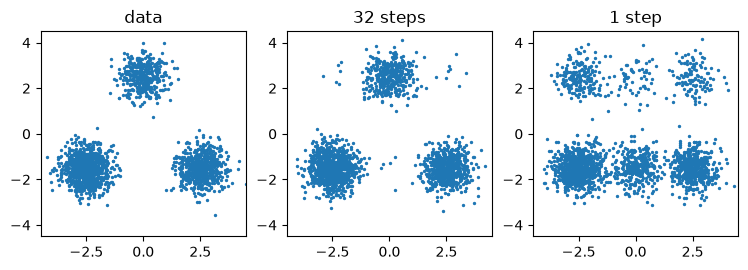

In [13]:
torch.manual_seed(1)
pairs = [quantize(mix.sample(2000))] + [
    unmask(pair_model, (2000, 2), S, alpha_bar, mask_id=K) for S in (32, 1)]
decode = lambda z: (z + torch.rand(len(z), 2)) / K * 10 - 5  # inside cell
d2l.scatter_panels([decode(z) for z in pairs], ['data', '32 steps', '1 step']);

<!-- d2l:prose id=discrete-diffusion-md-12 fw=all -->

### Images as Binary Tokens

Two tokens show the mechanism; an image shows it at scale. Masked
diffusion for images works on the discrete codes of a learned tokenizer
[@Chang.Zhang.Jiang.ea.2022]. Binary pixels stand in for such codes
here because they need no tokenizer. Thresholding Fashion-MNIST at half
intensity makes every pixel a token with two values, and a masked pixel
has a third. An image is then a sequence of 784 tokens on a grid, so the
network can be the chapter's U-Net (that section); it
takes the one-hot encoding as three input channels and returns the logits
of the clean pixel as two output channels.
The loss and the sampler are those of the pair, with a linear schedule of
$T = 100$ steps and the mask at index 2.

In [14]:
X, _, X_test, _ = d2l.load_fashion_mnist_pm1(binary=True)  # (n, 28, 28)
T_img = 100                                   # steps of the image chain
alpha_bar_img = 1 - torch.arange(T_img + 1, device=X.device) / T_img

class MaskedUNet(nn.Module):
    """d2l.UNet on one-hot pixels (black, white, mask); clean-pixel logits."""
    def __init__(self):
        super().__init__()
        self.unet = d2l.UNet(in_channels=3, out_channels=2)

    def forward(self, z, t):  # z: (n, 28, 28) in {0, 1, 2}
        x = F.one_hot(z, 3).float().permute(0, 3, 1, 2)
        return self.unet(x, t).permute(0, 2, 3, 1)  # (n, 28, 28, 2)

<!-- d2l:prose id=discrete-diffusion-md-13 fw=all -->

Training takes 6,000 updates on batches of 128 images, with a constant
learning rate and a moving average of the weights with a half-life of
1,000 updates.

In [15]:
torch.manual_seed(2)
def batch_fn():
    i = torch.randint(0, len(X), (128,), device=X.device)
    return X[i], torch.randint(1, T_img + 1, (128,), device=X.device)

loss_fn = lambda model, batch: masked_loss(  # per pixel
    model, *batch, alpha_bar_img, mask_id=2).mean() / (28 * 28)
_, unet, _ = d2l.train_regression(MaskedUNet().to(X.device), loss_fn,
                                  batch_fn, 6000)

<!-- d2l:prose id=discrete-diffusion-md-14 fw=all -->

We estimate the bound on 1,000 held-out images, with one random mask per
image and level, and compare it with the cross-entropy of a model that
treats pixels as independent, using the frequency of white at each
position in the training set.

In [16]:
X_eval = X_test[:1000]
with torch.inference_mode():
    bound = sum(masked_loss(unet, X_eval, torch.full_like(X_eval[:, 0, 0], t),
                            alpha_bar_img, mask_id=2).mean()
                for t in range(1, T_img + 1)) / T_img
white = X.float().mean(0).clamp(1e-6, 1 - 1e-6)  # frequency of white
indep = -torch.where(X_eval == 1, white.log(), (1 - white).log()).sum((1, 2))
bits = lambda nats: f'{nats / math.log(2) / (28 * 28):.3f} bits per pixel'
print(f'bound {bits(bound)}, independent pixels {bits(indep.mean())}')

bound 0.170 bits per pixel, independent pixels 0.702 bits per pixel


<!-- d2l:prose id=discrete-diffusion-md-15 fw=all -->

The bound is about 0.17 bits per pixel, against about 0.70 for
independent pixels: read as code lengths, about 135 bits for a held-out
garment instead of about 550. Independent pixels are a weak yardstick,
admittedly, since almost any model that looks at a pixel's neighbors beats
them by a wide margin. What the run does establish is the size of the
gap: a model of the dependence between pixels saves at least three
quarters of the code length of independent pixels, and the network has
learned enough of that dependence to do so. The fair rival would be a
model of the same size that reveals the pixels one at a time in raster
order. We do not train one here;
that section reports how masked diffusion
and left-to-right models compare on text.

The sampler draws 1,000 images in a hundred steps; the grid shows the
first 48.

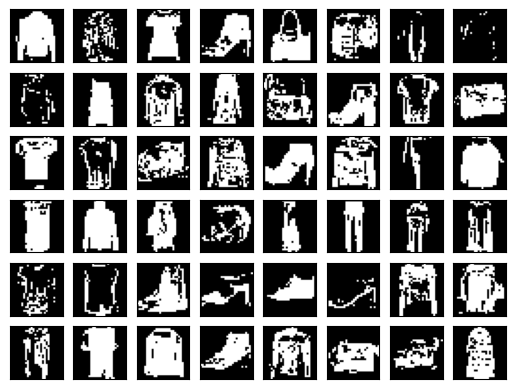

In [17]:
torch.manual_seed(3)
z100 = unmask(unet, (1000, 28, 28), T_img, alpha_bar_img, mask_id=2)
d2l.show_gray(z100[:48], 6, 8, scale=0.8);

<!-- d2l:prose id=discrete-diffusion-md-16 fw=all -->

Most samples are recognizable binary garments, rougher than the
gray-level samples of the earlier sections; about one in five is a
fragment or nearly empty. Six thousand updates leave the U-Net
undertrained, which is acceptable here: the experiment is about the bound
and the number of steps, not about the best garment. Each of the hundred
jumps reveals about eight pixels, drawn from predictions that see every
pixel revealed in earlier jumps. The next grid uses four jumps of about
200 pixels each.

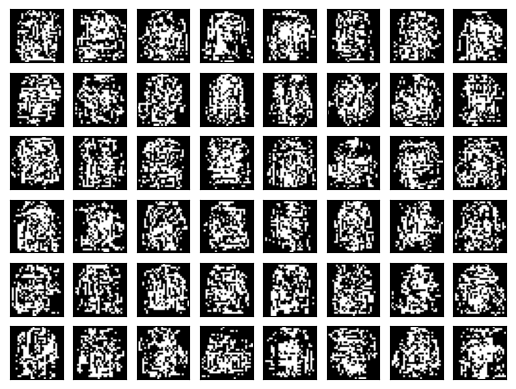

In [18]:
z4 = unmask(unet, (1000, 28, 28), 4, alpha_bar_img, mask_id=2)
d2l.show_gray(z4[:48], 6, 8, scale=0.8);

<!-- d2l:prose id=discrete-diffusion-md-17 fw=all -->

No garment survives. The first jump draws its pixels independently from
predictions for an all-mask image, which know only where garments tend to
be, and every later jump conditions on this noise. What remains is a
garment's outline, more often an average garment's than any particular
one's, filled with texture.

To measure what four steps lose, we count *speckles*, pixels that differ
from all four of their neighbors, in 1,000 images of each kind, and print
each fraction with its standard error over the 1,000 images. A third
batch takes 784 jumps, one pixel per jump on average, to show what a
hundred steps still lose. The chain's hundred levels cannot carry that
many jumps: `unmask` rounds its levels to the chain's, and a jump between
two equal levels reveals nothing. These jumps therefore run on a linear
schedule of 784 levels of their own. Most of their times $k/784$ fall
between the hundred times the network was trained at (the last seven lie
below the smallest), and the number of masked pixels tells it the time in
any case.

In [19]:
def speckles(z):
    """Per image, the fraction of interior pixels unlike all four neighbors."""
    c = z[:, 1:-1, 1:-1]
    unlike = ((c != z[:, :-2, 1:-1]) & (c != z[:, 2:, 1:-1])
              & (c != z[:, 1:-1, :-2]) & (c != z[:, 1:-1, 2:]))
    return unlike.float().mean((1, 2))

alpha_bar_784 = 1 - torch.arange(785, device=X.device) / 784  # 784 levels
z784 = unmask(unet, (1000, 28, 28), 784, alpha_bar_784, mask_id=2)
for name, z in (('data', X[:1000]), ('784 steps', z784), ('100 steps', z100),
                ('4 steps', z4)):
    per_image = speckles(z)
    print(f'{name:>9}: speckles {per_image.mean():.4f}, standard error over '
          f'the 1,000 images {per_image.std() / len(z) ** 0.5:.5f}')

     data: speckles 0.0037, standard error over the 1,000 images 0.00016
784 steps: speckles 0.0047, standard error over the 1,000 images 0.00016
100 steps: speckles 0.0075, standard error over the 1,000 images 0.00021
  4 steps: speckles 0.0330, standard error over the 1,000 images 0.00027


<!-- d2l:prose id=discrete-diffusion-md-18 fw=all -->

The data have about four speckles per thousand interior pixels, and the
four-step samples about nine times as many: the image counterpart of the
phantom blobs of the one-step pair. The hundred-step samples have about
twice the data's count, and there two causes mix: about eight pixels
still appear per jump, and the network is imperfect after 6,000 updates.
The 784-step row pulls them apart. More jumps shrink the independence
error and leave the network's own error where it was, as on the pair, and
one pixel per jump removes two thirds to three quarters of the
hundred-step excess. Could the draw of the images alone produce that
drop? Both rows come from the same network, so the 1,000 images of each
are the only chance in the comparison. Each count is a mean over
independent images, with a standard error of 0.00016 to 0.0002, and the
difference of two such means has one of about 0.00026; the drop is about
ten times that. Most of what a hundred steps lose is therefore the
independence error, not the network. The rest, which leaves the 784-step
samples with about 1.3 times the data's speckles, still about four
standard errors of a difference above the data, is the network's own
error plus what little independence remains when a pixel seldom shares
its jump with a neighbor; Exercise
2e separates the two.

## Neighbors and Retrospect

This section has treated masked diffusion on its own terms. Its
neighbors in the book are the language models of that section and
that section, and its ancestors are the earlier sections of
this chapter.

### Diffusion and Autoregression

A reader who has trained the language model of that section will
want to know how it relates to this one. The two-token tables answer, once
we sort samplers by the number of tokens they reveal per step.

Reveal one token per step in a fixed order, left to right, and the
sampler has the form of the language model of that section. Its
conditionals are the network's predictions at inputs with an unmasked
prefix and a masked rest.
On the pair this is the fixed-order row of the table of four orders, at
distance $0.000$ from $p$: with exact conditionals, a chain of one-token
reveals is exact, and its loss is the entropy.

Reveal one token per step in a uniformly random order, and the sampler is
an *order-agnostic autoregressive model* [@Uria.Murray.Larochelle.2014],
whose loss averages the negative log-likelihoods of all orders.
@Hoogeboom.Gritsenko.Bastings.ea.2022 showed that this loss is the
continuous-time bound of that section for a network
that ignores the time (Exercise 6
derives it with a Beta integral), and @Ou.Nie.Xue.ea.2025 that
ignoring the time loses nothing, since the best prediction for a masked
token depends only on the tokens already revealed. A masked diffusion model is thus trained as a
language model over all orders at once. For an exact network every order
gives the same joint likelihood, the entropy of the data, so its
continuous-time bound is tight. This is the floor of the pair seen from
the orders: as $T \to \infty$ no two tokens are revealed together, and
the excess $I/T$ vanishes.

Reveal several tokens per step, and the sampler incurs the independence
error: on the pair, $S$ jumps draw $1/S$ of the mass from the product of
the marginals, and a $T$-step bound rises by $I/T$. In exchange, $S$ network
evaluations generate $L$ tokens, where a left-to-right model needs $L$.

The two kinds of evaluation are not the same size, though. A left-to-right
model that caches its keys and values (that section) processes
one new token per step. The denoiser has no causal mask, so a revealed
token changes the activations at every position, nothing can be cached,
and each evaluation is a full pass over all $L$ positions. Counted in
token passes the costs are about $L$ against $S L$. Parallel decoding
therefore saves sequential steps, and with them latency, while its total
arithmetic is typically higher. Fast-dLLM [@Wu.Zhang.Xue.ea.2026]
recovers part of it by reusing approximate caches across steps, and block
diffusion [@Arriola.Gokaslan.Chiu.ea.2025] by decoding block after
block with an exact cache over the finished blocks.

At the far end stands BERT [@Devlin.Chang.Lee.ea.2018], which hides
15% of the tokens of a text and predicts them from both sides; the masked
language model of that section does the same, masking each
byte with probability 15%. Restricted to this single masking level, the
loss the equation becomes their masked-token
objective, the summed negative log-likelihood of the hidden tokens, up to
BERT's replacement of some masks by random or unchanged tokens. A masked
language model is thus a discrete diffusion model with one step
[@Austin.Johnson.Ho.ea.2021], though one that has seen a single
masking level; a sampler starting from the all-mask sequence would show
it inputs far from anything it was trained on.

Between these extremes sit today's diffusion language models, whose
denoiser is a transformer without the causal mask, with an extra
vocabulary entry for $[\textrm{M}]$ and no time input
[@Nie.Zhu.You.ea.2025]. What do they gain? Not likelihood where data are plentiful: with fresh
data throughout, masked diffusion needs a constant factor more compute
than an autoregressive model to reach the same loss
[@Nie.Zhu.Du.ea.2025]. When data are scarce and repeated many times,
it can come out ahead [@Prabhudesai.Wu.Zadeh.ea.2025], which the
authors attribute to the random masks acting as data augmentation. The
case for these models rests on parallel decoding, which writes many tokens
per network evaluation and so needs fewer sequential steps, and on infilling, which conditions on text on
both sides of a gap.

### Diffusion Models in Retrospect

Apart from its further reading, the chapter ends here, and with it the
Advanced part, so let us look back once. One idea carried every section:
a network that predicts the clean point from a noisy one, at every noise
level, is a generator, and a sampler turns its predictions into data by
integrating them. For tokens the noisy point became a partly erased
sequence, the prediction a distribution over the erased values and the
integration a sequence of reveals; the bound carried over unchanged.

Each part of that answer has a drawback, and a practitioner meets all of
them. The density arrives as a bound, and the weighting that gives the
best bound is not the one that gives the best samples
(that section). A regression replaces the
adversarial game of that section, but sampling calls the network
many times: a thousand for the original DDPM chain, a few tens with a
good solver (that section), and a handful only after
a second training run that distills a student
(that section). A latent space makes large images
affordable but adds a second model, the autoencoder, trained first and
then frozen (that section). And for text, many tokens
per evaluation bring the independence error, and the sampler cannot take
back what it wrote.

Several questions remain open. Few-step students trained along their
teacher's trajectories still trail it. The students that match or pass
their teachers add a critic to distribution matching, and give up the map
from noise to sample (that section). No single weighting is known to give both the best likelihood
and the best samples. Whether the compute gap between masked diffusion
and autoregression on text persists at the largest scales is being
decided by experiments far larger than any in this book; the Language
Models part returns to diffusion language models among the architectures
it surveys (that section).

## Summary

Discrete diffusion corrupts categorical tokens via row-stochastic transition matrices $\mathbf{Q}_t$; under the absorbing kernel, each token survives $t$ steps with probability $\bar\alpha_t = \prod_{s \le t}(1 - \beta_s)$ and is otherwise replaced by $[\textrm{M}]$. Its variational bound on the negative log-likelihood simplifies to a weighted sum of masked-token cross-entropies with weight $w_t = (\bar\alpha_{t-1} - \bar\alpha_t)/(1 - \bar\alpha_t)$ ($1/t$ under a linear schedule) and continuous-time limit $\int_0^1 \frac{1}{u}\, \mathbb{E}_u[\ell]\, du$, where independent masking renders the optimal clean-token distribution at a masked position time-agnostic. Because the reverse model factorizes across positions within each step, unmasking multiple tokens simultaneously incurs an independence error: on a two-token distribution $p$, $S$ equal linear jumps sample from $(1 - 1/S)p + (1/S)p^1 \otimes p^2$ with total variation error proportional to $1/S$, and the $T$-step bound floor exceeds the entropy $H(X^1, X^2)$ by $I(X^1; X^2)/T$. Viewed across unmasking schedules, masked diffusion connects classical sequence models: revealing one token per step left to right recovers autoregressive modeling (that section), revealing one token per step in a random order recovers order-agnostic autoregression, and training at a single masking rate $u = 0.15$ recovers BERT (that section).

## Exercises

1. **The uniform kernel.** Let the forward chain use the uniform kernel
   $\mathbf{Q}_t = (1 - \beta_t)\, \mathbf{I} + \beta_t\, \tfrac{1}{K}\mathbf{1}\mathbf{1}^\top$
   with $\beta_t > 0$ at every step.
    1. Show that
       $\bar{\mathbf{Q}}_t = \bar{\alpha}_t\, \mathbf{I} + (1 - \bar{\alpha}_t)\, \tfrac{1}{K}\mathbf{1}\mathbf{1}^\top$
       and that $\mathbf{x}_t = \mathbf{x}_0$ with probability
       $\bar{\alpha}_t + (1 - \bar{\alpha}_t)/K$. A token that shows a
       value at step $t$ may therefore have been resampled. Which question
       about every position does a network have to answer under this
       kernel but not under the absorbing kernel?
    1. Derive the posterior
       $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)$ from
       the equation, treating the cases
       $\mathbf{x}_t = \mathbf{x}_0$ and $\mathbf{x}_t \neq \mathbf{x}_0$
       separately. Show that for $t \geq 2$ every one of the $K$ values
       has positive probability, unlike under the two-point
       posterior the equation.
    1. The divergence terms of the bound compare this posterior with the
       reverse model at every position. Why are they more expensive to
       evaluate than the summand of the equation?

1. [code] **Pairs revealed together.** Let the sampler use the levels
   $T = t_0 > t_1 > \cdots > t_S = 0$ under a schedule with
   $\bar{\alpha}_0 = 1$ and $\bar{\alpha}_T = 0$, and write
   $\Delta_k = \bar{\alpha}_{t_{k+1}} - \bar{\alpha}_{t_k}$ for the
   increase of $\bar{\alpha}$ in jump $k$, where $k = 0, \ldots, S - 1$.
    1. In the coarser chain on the levels $t_k$, a token is
       revealed in jump $k$ with probability $\Delta_k$, independently of
       the other positions. Show that two tokens are revealed in the same
       jump with probability $\rho = \sum_k \Delta_k^2$, and that, among
       all $S$ increments that sum to one, equal increments
       $\Delta_k = 1/S$ minimize $\rho$.
    1. Show that with an exact network the sampler draws the two tokens
       of the quantized mixture from
       $(1 - \rho)\, p + \rho\, p^1 \otimes p^2$.
    1. For a sequence of $L$ tokens and equal increments, compute the
       expected number of pairs of tokens revealed in the same jump. How
       many steps keep it below one for $L = 1024$? Why does this count
       overstate the error of the sampler on text?
    1. A jump that reveals no token leaves the input of the next jump
       unchanged. A sampler whose network ignores the time, as the exact
       network does by Exercise 4a,
       can therefore draw the reveal decisions first and evaluate the
       network only in the jumps that reveal at least one token. Show that
       with $S$ equal jumps under the linear schedule the expected number
       of evaluations is $S\, (1 - (1 - 1/S)^L)$ for $L$ tokens. Evaluate
       it for the pair with $S = 32$, for the binary images with $S = 100$
       and $S = 784$, and for $L = S = 1024$.
    1. The 784-step samples of that section
       keep a quarter to a third of the hundred-step excess of speckles.
       Show that with $S$ equal jumps an interior pixel shares its jump
       with at least one of its four neighbors with probability
       $1 - (1 - 1/S)^4$, and evaluate it for $S = 4$, $100$ and $784$.
       Then train `unet` for twice as many updates and count the speckles
       at 100 and at 784 jumps again. Which count falls, and what does that
       say about the share of the remaining excess that is the network's?

1. **Two reverse parameterizations.** ● The reverse model
   the equation averages the posterior over
   the network's prediction. @Austin.Johnson.Ho.ea.2021 instead
   set

   $$p_{\boldsymbol{\theta}}(\mathbf{x}_{t-1} \mid \mathbf{x}_t) \propto \sum_{\hat{\mathbf{x}}_0} q(\mathbf{x}_{t-1}, \mathbf{x}_t \mid \hat{\mathbf{x}}_0)\, \tilde{p}_{\boldsymbol{\theta}}(\hat{\mathbf{x}}_0 \mid \mathbf{x}_t)$$

   for a network output $\tilde{p}_{\boldsymbol{\theta}}$, which
   reweights each candidate by $q(\mathbf{x}_t \mid \hat{\mathbf{x}}_0)$.
   For most kernels the two forms differ.
   Let $q(\mathbf{x}_0 \mid \mathbf{x}_t)$ and
   $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$ denote the conditionals of the
   forward process started from the data.
    1. Take a single token. Show that if the prediction in
       the equation equals
       $q(\mathbf{x}_0 \mid \mathbf{x}_t)$, the reverse model is the true
       reverse transition $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$, for
       every kernel.
    1. Show that under the absorbing kernel the weight
       $q(\mathbf{x}_t \mid \hat{\mathbf{x}}_0)$ is the same for every
       candidate at a masked position, so that the two forms agree.

1. [code] **Time-agnostic predictions.** ● This section argued that under
   the absorbing kernel the best prediction at a masked position does not
   depend on $t$ [@Ou.Nie.Xue.ea.2025].
    1. Write the argument as a short proof. Which property of the
       absorbing forward process does it use? Does the same hold for the
       uniform kernel?
    1. The masked language model of that section masks each
       token independently with probability 15%. By (a), its exact
       predictions are those that the sampler needs at mask patterns of
       that density. For sequences of $L = 512$ tokens, find the range of
       masked fractions that such a model sees in training, say within
       three standard deviations of 15%. What fraction of the steps of a run from the all-mask sequence,
       with $S = 512$ equally spaced levels under the linear schedule, shows
       the network a masked fraction in this range?
    1. `MaskedMLP` receives the time as an input. Fix the pattern in which
       the first token is masked and the second is observed, and compute
       the predictions of `pair_model` for all 32 values of the second
       token at $t \in \{1, 16, 31\}$, that is, at time inputs $t/32$. Then
       compute two kinds of Kullback–Leibler divergence, each averaged over
       the marginal of the second token: that of the predictions at
       $t = 16$ and at $t = 31$ from those at $t = 1$, and that of the
       predictions at each $t$ from the exact conditionals of `table`
       (clamp probabilities at $10^{-12}$). What do the sizes of the two
       kinds say about the use that the trained network makes of its time
       input?

1. [code] **Floor of an exact network.** ● Let a schedule with
   $\bar{\alpha}_0 = 1$ and $\bar{\alpha}_T = 0$ have the increments
   $\Delta_t = \bar{\alpha}_{t-1} - \bar{\alpha}_t$, and consider the two
   tokens of the quantized mixture.
    1. Show that the bound the equation of an exact
       network, averaged over the true table, is

       $$H(X^1, X^2) + I(X^1; X^2) \sum_{t=1}^{T} \Delta_t^2.$$

       Write the term of step $t$ with the three mask patterns and their
       probabilities; a telescoping sum of $(1 - \bar{\alpha}_t)^2$
       evaluates the sum over $t$. Check that the linear schedule gives
       $H(X^1, X^2) + I(X^1; X^2)/T$.
    1. Evaluate the sum for the schedule $\bar{\alpha}_t = 1 - (t/T)^2$ in
       closed form and at $T = 32$, and compare the floor with that of the
       linear schedule. Why does the choice of schedule cease to matter as
       $T \to \infty$?
    1. Write a function with the call signature of `MaskedMLP` that
       returns the logarithms of the exact conditionals computed from
       `table`, and of the marginals where both tokens are masked (clamp
       probabilities at $10^{-12}$). Pass it to `exact_bound` with each of
       the two schedules as `alpha_bar`.
    1. Train `MaskedMLP` with `masked_loss` under the schedule of (b),
       with the settings used for `pair_model`, and compare its exact bound
       with its floor and with the exact bound of `pair_model`.

1. **The order-agnostic bound.** ● Let a network ignore the time, as the
   exact network does by Exercise
   4a, and write
   $\ell(i, U) = -\log p_{\boldsymbol{\theta}}(\mathbf{x}_0^i \mid \mathbf{x}_0^U)$
   for its loss at position $i$ when exactly the positions in the set $U$
   are unmasked. The continuous-time limit of the bound in
   that section, written as an integral over the
   masking probability $u$, is then a weighted sum of the losses
   $\ell(i, U)$ over $i \notin U$.
   @Hoogeboom.Gritsenko.Bastings.ea.2022 and
   @Ou.Nie.Xue.ea.2025 show that it equals the expected negative log-likelihood of an order-agnostic
   autoregressive model [@Uria.Murray.Larochelle.2014],

   $$\mathbb{E}_{\sigma} \Big[ \sum_{k=1}^{L} -\log p_{\boldsymbol{\theta}}\big(\mathbf{x}_0^{\sigma(k)} \mid \mathbf{x}_0^{\sigma(1)}, \ldots, \mathbf{x}_0^{\sigma(k-1)}\big) \Big],$$

   where $\sigma$ is a uniformly random permutation of the $L$ positions.
    1. Find the weight of $\ell(i, U)$ in the integral when
       $|U| = L - m$. The Beta integral
       $\int_0^1 u^{m-1} (1 - u)^{L-m}\, du = (m-1)!\, (L-m)! / L!$
       evaluates it.
    1. Find the probability that a random order reveals the positions of
       $U$ first and position $i$ next, and conclude that the two
       expressions agree.
    1. Every order gives the same value for an exact network. Which value
       is it? Compare with Exercise
       5a as
       $T \to \infty$.
    1. Use Jensen's inequality to show that the expression also bounds the
       negative log-likelihood of the model that draws an order uniformly
       at random and then samples the tokens in that order.

1. [extended] **A masked diffusion language model.** ●●
   @Prabhudesai.Wu.Zadeh.ea.2025 report that masked diffusion
   models make better use of repeated data than autoregressive models.
   This problem repeats the data on purpose. Use the character-level
   windows `d2l.TimeMachine(batch_size=64, num_steps=128,
   tokenization='char', num_train=100000, num_val=3000)` of
   that section, whose 100,000 training windows start at
   the first 100,000 positions of *The Time Machine*; 2,000 updates on
   minibatches of 64 windows of 128 characters then pass over these
   positions about 160 times.
    1. Train the `GPT` of that section on these windows for 2,000
       updates with its recipe, `LMOptimizer`, and record its training and
       validation losses every 200 updates. At which update does the
       validation loss reach its minimum, and what do the two losses do
       after it?
    1. Build the denoiser as a subclass of `d2l.GPT` with `vocab_size + 1`
       tokens, the last one the mask, and a forward pass that accepts the
       time and ignores it, as this section's argument allows. (Hint: to
       drop the causal mask, override the nested class `CausalAttention`
       and call the framework's fused attention without the mask.) Train
       it with `masked_loss` and the linear `alpha_bar` of $T = 128$ steps
       for 2,000 updates.
    1. Every 200 updates, estimate its bound in bits per character on the
       validation windows, with several masks per window. Plot it next to
       the validation loss of `GPT` in bits per character. Compare the
       best value of each curve and the update at which it is reached.
       Expect the denoiser's bound to stay well above the loss of `GPT`
       at every update before `GPT` begins to overfit: the gap is the
       cost that the scaling studies measure, not a bug.
    1. Continue training the denoiser to 8,000 updates if its bound still
       falls at update 2,000. Which model begins to overfit later? How
       does training on randomly masked windows change what the denoiser
       can memorize from a window it has seen many times?
    1. Sample windows with $S \in \{128, 32, 8\}$ steps and compare them
       with samples of `GPT`. Where do the few-step samples fail? Relate
       the failures to Exercise
       2c.

[Discussions](https://d2l.discourse.group/t/36825)